# Advanced DL models: Residual MLP and Feature Transformer

Your CNN and RNN were weak fits because they assume the feature order means something. These two are designed for **tabular data** and do not make that assumption.

| Model | Idea | Why it fits |
|---|---|---|
| **Residual MLP (tabular ResNet)** | An MLP whose blocks add their input back to their output (skip connections), with batch normalisation | Trains deeper networks reliably. A strong, simple tabular baseline in the research literature |
| **Feature Transformer (FT-Transformer style)** | Each feature becomes a "token". Self-attention then lets every feature look at every other feature, and the model learns which feature interactions matter | Attention has no notion of feature order, so it fixes the CNN/RNN problem, and it is a current deep-learning approach for tabular data |

**Feasibility:** both run on CPU. The Transformer is the slowest model in your project (45 tokens per flow), so lower `TRANSFORMER_EPOCHS` or `D_MODEL` if it drags. Neither is guaranteed to beat XGBoost on tabular data, so report what you find.

Needs `nids_layers.py` in the same folder. Run after the preprocessing notebook.

## 1. Imports

In [1]:
# %pip install tensorflow matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
import keras
from keras import layers

from nids_layers import FeatureTokenizer      # custom layer (file in the same folder)

print("keras", keras.__version__)

keras 3.15.1


## 2. Config

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

LEARNING_RATE = 1e-3
BATCH_SIZE = 512
PATIENCE = 8

# Residual MLP
RES_WIDTH = 128
RES_BLOCKS = 3
RES_DROPOUT = 0.25
RES_EPOCHS = 60

# Feature Transformer
D_MODEL = 32            # size of each feature token
N_HEADS = 4
N_BLOCKS = 2
FF_DIM = 64
TR_DROPOUT = 0.1
TRANSFORMER_EPOCHS = 40

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 4. Helpers (same evaluation as every other notebook, now with accuracy)

In [4]:
def ms_per_1000(predict_fn, X, n=5000):
    """Prediction time in milliseconds per 1,000 flows (a model that is too slow cannot run live)."""
    Xs = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xs)
    return round(1e6 * (time.perf_counter() - t0) / len(Xs), 1)


def report_binary(y_true, pred, title, score=None, ms=None):
    print(classification_report(y_true, pred, target_names=["Normal", "Attack"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1)
    if score is not None:
        print(f"ROC-AUC:              {roc_auc_score(y_true, score):.4f}")
    print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
    print(f"False negative rate:  {fn / max(fn + tp, 1):.4f}  ({fn} attacks missed)")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
    ax.set_title(f"{title}: validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": title,
            "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "false_pos_rate": fpr,
            "ms_per_1000_flows": ms}


def report_multiclass(y_true, pred, title, ms=None):
    labels = list(range(n_classes))
    print(classification_report(y_true, pred, labels=labels, target_names=class_names,
                                digits=4, zero_division=0))
    print("macro F1:    %.4f" % f1_score(y_true, pred, average="macro"))
    print("weighted F1: %.4f" % f1_score(y_true, pred, average="weighted"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
    axes[1].set_title("Row-normalised (share of each true class)")
    plt.suptitle(f"{title}: validation confusion matrices")
    plt.tight_layout()
    plt.show()
    flagged = np.asarray(pred) != 0          # class 0 is Normal
    rows = []
    for i, name in enumerate(class_names):
        m = np.asarray(y_true) == i
        rows.append({"true class": name, "flows": int(m.sum()),
                     "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                     "correct type (%)": round(100 * (np.asarray(pred)[m] == i).mean(), 2)})
    display(pd.DataFrame(rows))
    return {"model": title + " (macro)",
            "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, pred, average="macro"),
            "false_pos_rate": np.nan,
            "ms_per_1000_flows": ms}

In [5]:
keras.utils.set_random_seed(SEED)


def head(x, n_out, binary):
    if binary:
        return layers.Dense(1, activation="sigmoid")(x)
    return layers.Dense(n_out, activation="softmax")(x)


def compile_model(model, binary):
    if binary:
        loss, metrics = "binary_crossentropy", [keras.metrics.AUC(name="auc")]
    else:
        loss, metrics = "sparse_categorical_crossentropy", ["accuracy"]
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=loss, metrics=metrics)
    return model


def fit_model(model, X_tr, y_tr, X_va, y_va, class_weight):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]
    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=CURRENT_EPOCHS,
                     batch_size=BATCH_SIZE, class_weight=class_weight,
                     callbacks=callbacks, verbose=2)
    print(f"trained {len(hist.history['loss'])} epochs in {time.time() - t0:.1f}s")
    return hist


def plot_history(hist, metric, title):
    h = hist.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="train")
    axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h[metric], label="train")
    axes[1].plot(h["val_" + metric], label="validation")
    axes[1].set_title(metric.upper()); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

## 5. The two architectures

In [6]:
def build_resnet(n_in, n_out, binary):
    """Residual MLP: Dense -> [BN, Dense, ReLU, Dropout, Dense, Dropout, + skip] x N -> BN -> head."""
    inputs = keras.Input(shape=(n_in,))
    x = layers.Dense(RES_WIDTH)(inputs)
    for _ in range(RES_BLOCKS):
        h = layers.BatchNormalization()(x)
        h = layers.Dense(RES_WIDTH * 2, activation="relu")(h)
        h = layers.Dropout(RES_DROPOUT)(h)
        h = layers.Dense(RES_WIDTH)(h)
        h = layers.Dropout(RES_DROPOUT)(h)
        x = layers.Add()([x, h])                       # the skip connection
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return keras.Model(inputs, head(x, n_out, binary))


def transformer_block(x):
    attn = layers.MultiHeadAttention(num_heads=N_HEADS, key_dim=D_MODEL // N_HEADS, dropout=TR_DROPOUT)(x, x)
    x = layers.LayerNormalization(epsilon=1e-6)(x + attn)
    ff = layers.Dense(FF_DIM, activation="gelu")(x)
    ff = layers.Dropout(TR_DROPOUT)(ff)
    ff = layers.Dense(D_MODEL)(ff)
    return layers.LayerNormalization(epsilon=1e-6)(x + ff)


def build_transformer(n_in, n_out, binary):
    """Each feature -> token -> self-attention blocks -> average over tokens -> head."""
    inputs = keras.Input(shape=(n_in,))
    x = FeatureTokenizer(n_in, D_MODEL)(inputs)
    for _ in range(N_BLOCKS):
        x = transformer_block(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(TR_DROPOUT)(x)
    return keras.Model(inputs, head(x, n_out, binary))

## 6. Train, evaluate and save both models

One function trains the binary and multiclass versions of a model, prints the usual reports and saves the results.


==================== Residual MLP: binary ====================
Epoch 1/60
274/274 - 6s - 22ms/step - auc: 0.9714 - loss: 0.2117 - val_auc: 0.9876 - val_loss: 0.1360 - learning_rate: 0.0010
Epoch 2/60
274/274 - 4s - 13ms/step - auc: 0.9826 - loss: 0.1638 - val_auc: 0.9895 - val_loss: 0.1380 - learning_rate: 0.0010
Epoch 3/60
274/274 - 4s - 13ms/step - auc: 0.9847 - loss: 0.1528 - val_auc: 0.9904 - val_loss: 0.1207 - learning_rate: 0.0010
Epoch 4/60
274/274 - 4s - 13ms/step - auc: 0.9859 - loss: 0.1468 - val_auc: 0.9907 - val_loss: 0.1261 - learning_rate: 0.0010
Epoch 5/60
274/274 - 4s - 13ms/step - auc: 0.9863 - loss: 0.1440 - val_auc: 0.9909 - val_loss: 0.1208 - learning_rate: 0.0010
Epoch 6/60
274/274 - 4s - 13ms/step - auc: 0.9871 - loss: 0.1397 - val_auc: 0.9912 - val_loss: 0.1191 - learning_rate: 0.0010
Epoch 7/60
274/274 - 4s - 13ms/step - auc: 0.9874 - loss: 0.1377 - val_auc: 0.9913 - val_loss: 0.1246 - learning_rate: 0.0010
Epoch 8/60
274/274 - 4s - 13ms/step - auc: 0.9878 - lo

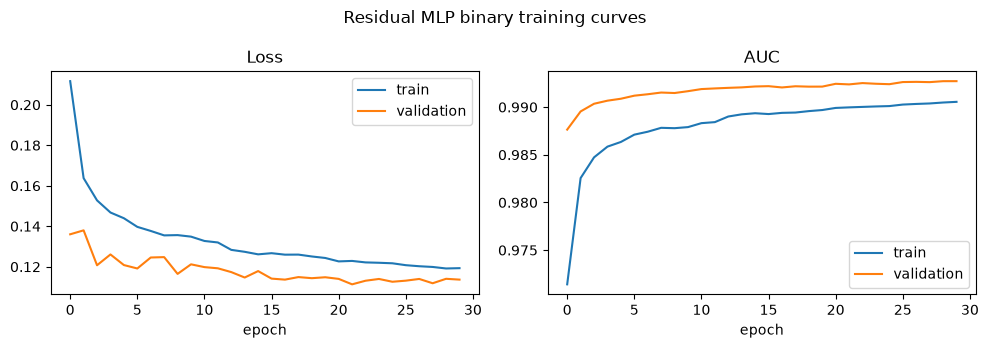

              precision    recall  f1-score   support

      Normal     0.8681    0.9622    0.9127     11200
      Attack     0.9813    0.9314    0.9557     23869

    accuracy                         0.9412     35069
   macro avg     0.9247    0.9468    0.9342     35069
weighted avg     0.9452    0.9412    0.9420     35069

ROC-AUC:              0.9926
False positive rate:  0.0378  (423 normal flows flagged as attacks)
False negative rate:  0.0686  (1638 attacks missed)


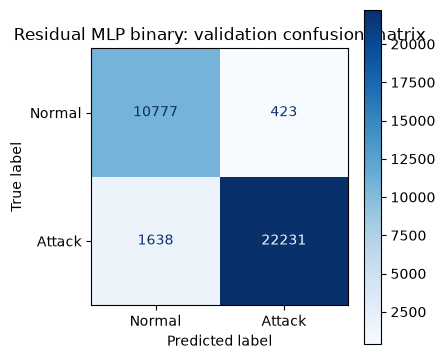


==================== Residual MLP: multiclass ====================
Epoch 1/60
274/274 - 6s - 22ms/step - accuracy: 0.6862 - loss: 0.9831 - val_accuracy: 0.7567 - val_loss: 0.6184 - learning_rate: 0.0010
Epoch 2/60
274/274 - 3s - 12ms/step - accuracy: 0.7363 - loss: 0.8247 - val_accuracy: 0.7742 - val_loss: 0.5664 - learning_rate: 0.0010
Epoch 3/60
274/274 - 3s - 12ms/step - accuracy: 0.7448 - loss: 0.7855 - val_accuracy: 0.7744 - val_loss: 0.5542 - learning_rate: 0.0010
Epoch 4/60
274/274 - 3s - 12ms/step - accuracy: 0.7497 - loss: 0.7647 - val_accuracy: 0.7746 - val_loss: 0.5541 - learning_rate: 0.0010
Epoch 5/60
274/274 - 3s - 13ms/step - accuracy: 0.7520 - loss: 0.7561 - val_accuracy: 0.7781 - val_loss: 0.5425 - learning_rate: 0.0010
Epoch 6/60
274/274 - 3s - 12ms/step - accuracy: 0.7541 - loss: 0.7465 - val_accuracy: 0.7803 - val_loss: 0.5320 - learning_rate: 0.0010
Epoch 7/60
274/274 - 3s - 12ms/step - accuracy: 0.7562 - loss: 0.7376 - val_accuracy: 0.7819 - val_loss: 0.5282 - le

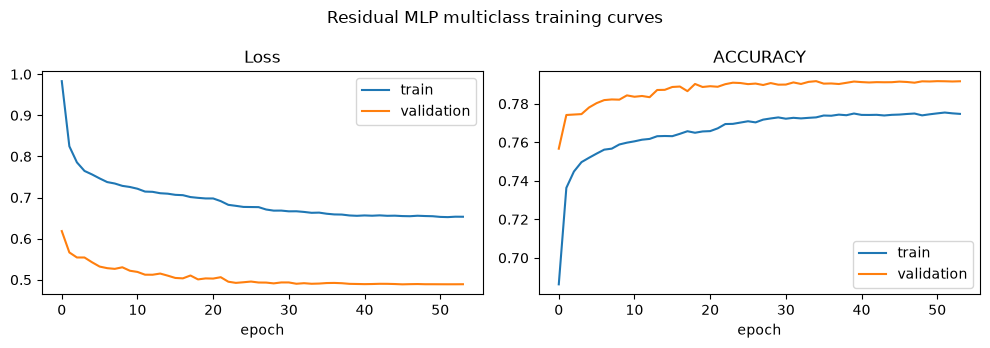

                precision    recall  f1-score   support

        Normal     0.9974    0.8496    0.9176     11200
           DoS     0.3346    0.8214    0.4755      2453
Reconnaissance     0.8113    0.8090    0.8101      2099
       Fuzzers     0.6552    0.8653    0.7457      3637
      Exploits     0.8675    0.4695    0.6092      6678
       Generic     0.9999    0.9805    0.9901      8000
         Other     0.3504    0.4022    0.3745      1002

      accuracy                         0.7915     35069
     macro avg     0.7166    0.7425    0.7032     35069
  weighted avg     0.8617    0.7915    0.8047     35069

macro F1:    0.7032
weighted F1: 0.8047


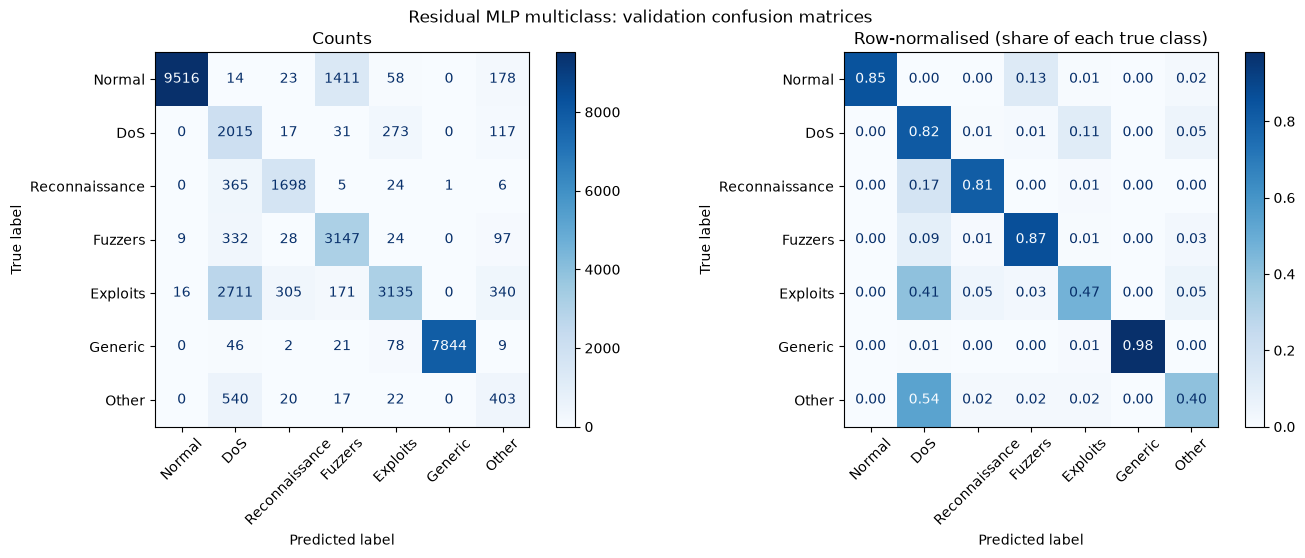

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,15.04,84.96
1,DoS,2453,100.00,82.14
2,Reconnaissance,2099,100.00,80.90
3,Fuzzers,3637,99.75,86.53
4,Exploits,6678,99.76,46.95
5,Generic,8000,100.00,98.05
6,Other,1002,100.00,40.22


In [7]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)


def run_model(tag, name, builder, epochs):
    global CURRENT_EPOCHS
    CURRENT_EPOCHS = epochs
    print(f"\n{'=' * 20} {name}: binary {'=' * 20}")
    m_bin = compile_model(builder(n_features, 1, True), True)
    h = fit_model(m_bin, X_train, yb_train, X_val, yb_val, cw_bin)
    plot_history(h, "auc", f"{name} binary training curves")
    proba = m_bin.predict(X_val, batch_size=4096, verbose=0).ravel()
    row_b = report_binary(yb_val, (proba >= 0.5).astype(int), f"{name} binary", score=proba,
                          ms=ms_per_1000(lambda X: m_bin.predict(X, batch_size=4096, verbose=0), X_val))

    print(f"\n{'=' * 20} {name}: multiclass {'=' * 20}")
    m_multi = compile_model(builder(n_features, n_classes, False), False)
    h = fit_model(m_multi, X_train, ym_train, X_val, ym_val, cw_multi)
    plot_history(h, "accuracy", f"{name} multiclass training curves")
    pred = m_multi.predict(X_val, batch_size=4096, verbose=0).argmax(axis=1)
    row_m = report_multiclass(ym_val, pred, f"{name} multiclass",
                              ms=ms_per_1000(lambda X: m_multi.predict(X, batch_size=4096, verbose=0), X_val))

    m_bin.save(mdir / f"{tag}_binary.keras")
    m_multi.save(mdir / f"{tag}_multiclass.keras")
    pd.DataFrame([row_b, row_m]).to_csv(mdir / f"{tag}_validation_summary.csv", index=False)
    return m_bin, m_multi


res_bin, res_multi = run_model("resmlp", "Residual MLP", build_resnet, RES_EPOCHS)


==================== Feature Transformer: binary ====================
Epoch 1/40
274/274 - 31s - 112ms/step - auc: 0.9655 - loss: 0.2324 - val_auc: 0.9850 - val_loss: 0.1427 - learning_rate: 0.0010
Epoch 2/40
274/274 - 26s - 95ms/step - auc: 0.9825 - loss: 0.1633 - val_auc: 0.9877 - val_loss: 0.1415 - learning_rate: 0.0010
Epoch 3/40
274/274 - 26s - 95ms/step - auc: 0.9842 - loss: 0.1545 - val_auc: 0.9895 - val_loss: 0.1426 - learning_rate: 0.0010
Epoch 4/40
274/274 - 28s - 102ms/step - auc: 0.9855 - loss: 0.1482 - val_auc: 0.9899 - val_loss: 0.1417 - learning_rate: 0.0010
Epoch 5/40
274/274 - 26s - 95ms/step - auc: 0.9862 - loss: 0.1440 - val_auc: 0.9902 - val_loss: 0.1477 - learning_rate: 0.0010
Epoch 6/40
274/274 - 25s - 93ms/step - auc: 0.9877 - loss: 0.1366 - val_auc: 0.9909 - val_loss: 0.1373 - learning_rate: 5.0000e-04
Epoch 7/40
274/274 - 26s - 95ms/step - auc: 0.9880 - loss: 0.1350 - val_auc: 0.9906 - val_loss: 0.1435 - learning_rate: 5.0000e-04
Epoch 8/40
274/274 - 26s - 96m

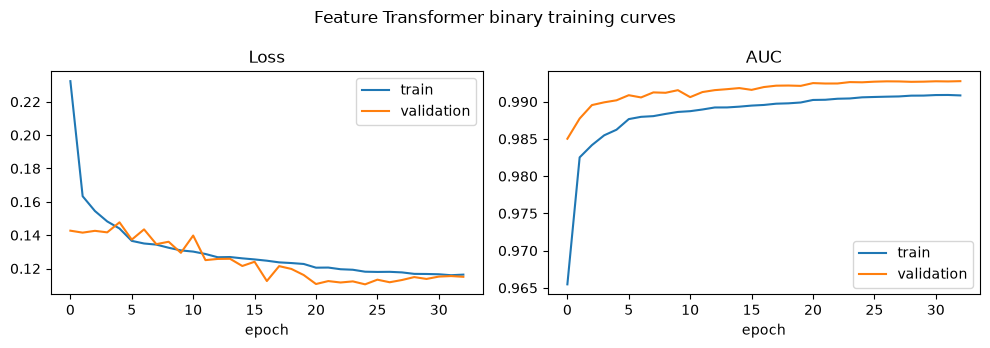

              precision    recall  f1-score   support

      Normal     0.8687    0.9635    0.9136     11200
      Attack     0.9819    0.9317    0.9561     23869

    accuracy                         0.9418     35069
   macro avg     0.9253    0.9476    0.9349     35069
weighted avg     0.9458    0.9418    0.9426     35069

ROC-AUC:              0.9930
False positive rate:  0.0365  (409 normal flows flagged as attacks)
False negative rate:  0.0683  (1631 attacks missed)


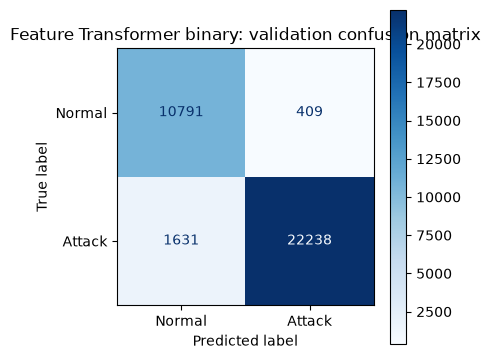


==================== Feature Transformer: multiclass ====================
Epoch 1/40
274/274 - 32s - 116ms/step - accuracy: 0.6595 - loss: 1.0623 - val_accuracy: 0.6887 - val_loss: 0.7012 - learning_rate: 0.0010
Epoch 2/40
274/274 - 25s - 93ms/step - accuracy: 0.7323 - loss: 0.8301 - val_accuracy: 0.7744 - val_loss: 0.5707 - learning_rate: 0.0010
Epoch 3/40
274/274 - 26s - 95ms/step - accuracy: 0.7476 - loss: 0.7690 - val_accuracy: 0.7798 - val_loss: 0.5527 - learning_rate: 0.0010
Epoch 4/40
274/274 - 26s - 94ms/step - accuracy: 0.7530 - loss: 0.7442 - val_accuracy: 0.7832 - val_loss: 0.5351 - learning_rate: 0.0010
Epoch 5/40
274/274 - 26s - 94ms/step - accuracy: 0.7581 - loss: 0.7288 - val_accuracy: 0.7827 - val_loss: 0.5277 - learning_rate: 0.0010
Epoch 6/40
274/274 - 28s - 103ms/step - accuracy: 0.7584 - loss: 0.7211 - val_accuracy: 0.7838 - val_loss: 0.5200 - learning_rate: 0.0010
Epoch 7/40
274/274 - 27s - 98ms/step - accuracy: 0.7603 - loss: 0.7152 - val_accuracy: 0.7840 - val_l

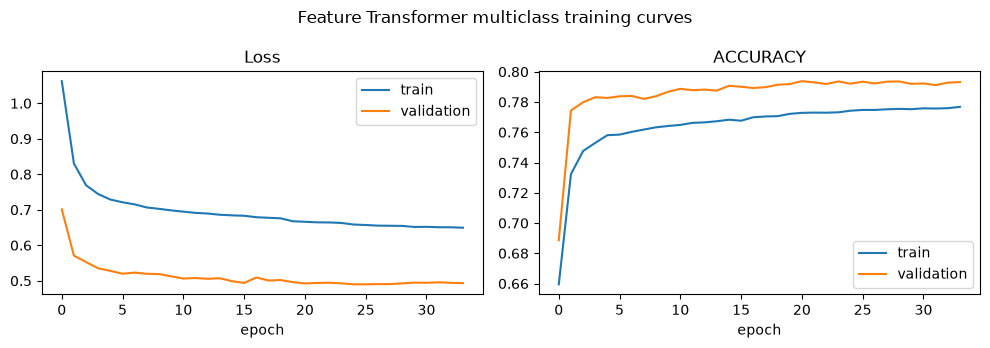

                precision    recall  f1-score   support

        Normal     0.9971    0.8483    0.9167     11200
           DoS     0.3363    0.8096    0.4752      2453
Reconnaissance     0.8283    0.8023    0.8151      2099
       Fuzzers     0.6478    0.8804    0.7464      3637
      Exploits     0.8655    0.4808    0.6182      6678
       Generic     1.0000    0.9801    0.9900      8000
         Other     0.3610    0.3992    0.3791      1002

      accuracy                         0.7934     35069
     macro avg     0.7194    0.7430    0.7058     35069
  weighted avg     0.8620    0.7934    0.8066     35069

macro F1:    0.7058
weighted F1: 0.8066


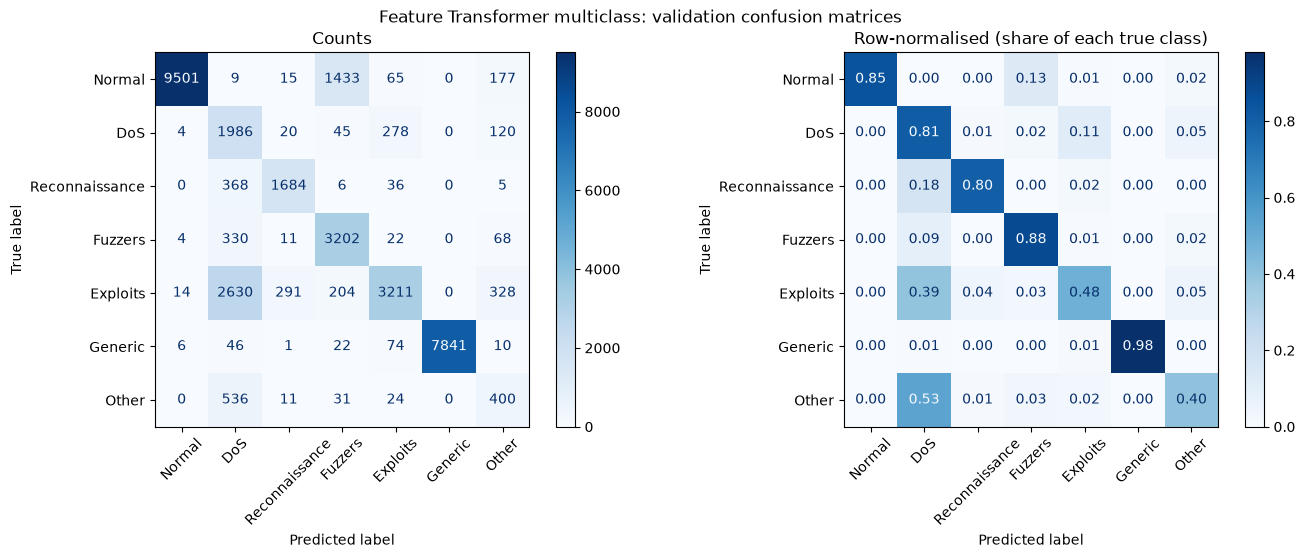

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,15.17,84.83
1,DoS,2453,99.84,80.96
2,Reconnaissance,2099,100.00,80.23
3,Fuzzers,3637,99.89,88.04
4,Exploits,6678,99.79,48.08
5,Generic,8000,99.92,98.01
6,Other,1002,100.00,39.92


In [8]:
tr_bin, tr_multi = run_model("fttransformer", "Feature Transformer", build_transformer, TRANSFORMER_EPOCHS)

## 7. Compare with every model run so far

In [9]:
# compare with every other model whose notebook has been run
frames = [pd.read_csv(f) for f in sorted(Path(MODEL_DIR).glob("*_validation_summary.csv"))]
pd.concat(frames, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate,ms_per_1000_flows,accuracy
0,Autoencoder binary,0.9666,0.6791,0.7977,0.0500,NaN,NaN
1,ANN binary,0.9763,0.9288,0.9520,0.0479,20.3,NaN
2,ANN multiclass (macro),0.7079,0.7254,0.6912,NaN,17.2,NaN
3,CatBoost binary,0.9846,0.9486,0.9663,0.0317,1.3,0.9549
4,CatBoost multiclass (macro),0.7072,0.7333,0.6968,NaN,1.6,0.7874
5,CNN binary,0.9757,0.9403,0.9577,0.0499,14.0,NaN
6,CNN multiclass (macro),0.7158,0.7336,0.7000,NaN,11.8,NaN
7,DNN binary,0.9791,0.9345,0.9563,0.0424,20.1,NaN
8,DNN multiclass (macro),0.7072,0.7316,0.6950,NaN,17.6,NaN
9,ExtraTrees binary,0.9811,0.9524,0.9665,0.0391,20.7,0.9551
